INSTALL PACKAGES FOR GRAPH DATA PRECOMPUTATION

FOR GRAPH DATA PROCESSING AND COMPUTATION, WE WILL USE v6e-1 TPU

In [ ]:
#### EVEN THOUGH DGL HAS CUDA VERSIONS BUT THEN THE PYTHON CUDA VRESION AVAIALBLE NOW ARE OLD AND WONT WORK IN THE CURRENT GOOGLE COLAB WITH PRE-INSTALLED CURRENT OR UP-TO-DATE CUDA DRIVERS
#### THAT IS WHY I USED TPU RUNTIME WHICH IS FAST ENOUGH FOR ALL GRAPH DATA PRE-COMPUTATIONS IN THIS WORK

In [ ]:
# MOUNT GOOGLE DRIVE
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# THEN INSTALL ALL REQUIRED PACKAGES THAT ARE NOT INSTALLED IN COLAB BY DEFAULT
!pip install torch==2.4.0
!pip install torch_geometric
!pip install  dgl -f https://data.dgl.ai/wheels/torch-2.4/repo.html
!pip install numpy==1.24.4
!pip install rdkit
!pip install graphein[extras]
!pip install ogb==1.3.6

Looking in links: https://data.dgl.ai/wheels/torch-2.4/repo.html
  Using cached numpy-1.24.4.tar.gz (10.9 MB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


IMPORT LIBRARIES AMD FUNCTIONS

In [ ]:
import os
import sys
import rdkit
import torch
import logging
import numpy as np
from tqdm import tqdm
import pandas as pd
import networkx as nx
from rdkit import RDLogger
from rdkit.Chem import AllChem
import graphein.molecule as gm
from ogb.lsc import PCQM4Mv2Dataset
from torch_geometric.data import Data
from utils.ogb_graph_generator import run_graph_generator   # make sure utils folder is in your current directory

## DOWNLOAD OGB DATASET, CONSTRUCT GRAPHS AND PE, AND ADD LABELS ##

DOWNLOAD OGB PCQMCMv2 DATASET DIRECTLY AND CLEAN PREP IT

In [ ]:
ROOT = "/content/drive/MyDrive/thesis/"
pcq = PCQM4Mv2Dataset(root = ROOT, only_smiles = True)

In [ ]:
len(pcq)

3746620

In [ ]:
# visualize first 15 samples

for i in range(15):
    print(pcq[i])

('O=C1[N]c2ccncc2[CH][C@@H]1c1ccc(cc1)C', 3.0476751256)
('COc1cc(OC)ccc1/C=C/N(C(=O)C)C', 4.410965516605)
('C=CCN(C(=O)C)/C=C/c1ccccc1C', 4.639541151025)
('C=CCN(C(=O)C)/C=C/c1ccccc1F', 4.492599671754999)
('C=CCN(C(=O)C)/C=C/c1ccccc1Cl', 4.612329765975001)
('CCN(C(=O)C)/C=C/c1ccccc1Cl', 4.478993979229999)
('COC(=O)CC[C@H]1O[C@@H]([C@@H]([C@@H]1O)O)OC', 7.102171498050001)
('CN[C@H](N/N=C(\\c1ccccn1)/C)S', 4.242254929294999)
('N[C@H](N/N=C(\\c1ccccn1)/C)S', 4.280350868365)
('O=C1C=C[C](C(=C1)N)C1=N[N]C(=S)N1N', 1.9592197236000004)
('CCCN1[C@@H](Cl)[C@@H](N(=O)=O)C(=NC1=O)O', 4.174226466670001)
('C[C@@H]1C[C@@H](C(=C)C)c2c([C@@H]1C)cc(c(c2)C)O', 5.776977046115)
('CC1=N[N][C@@H]2[C]1C(=O)N(c1c2cccn1)O', 3.68442153577)
('O/C(=C/C(=O)C)/C/C(=C\\C(=O)C)/O', 4.93614524807)
('OC(=O)/C=N/NOCc1ccncc1', 5.09397128136)


In [ ]:
# extract lists enteries and convert to pandas dataframe
# note that the two test datasets do not have assigned values because they are to be submitted to the leaderboard for comparison and evaluation

smiles = []
gap_val = []
for i in range(len(pcq)):
    smiles.append(pcq[i][0])
    gap_val.append(pcq[i][1])

pc_df = pd.DataFrame({'smiles': smiles, 'gap_val': gap_val})
pc_df

,smiles,gap_val
0,O=C1[N]c2ccncc2[CH][C@@H]1c1ccc(cc1)C,3.047675
1,COc1cc(OC)ccc1/C=C/N(C(=O)C)C,4.410966
2,C=CCN(C(=O)C)/C=C/c1ccccc1C,4.639541
3,C=CCN(C(=O)C)/C=C/c1ccccc1F,4.492600
4,C=CCN(C(=O)C)/C=C/c1ccccc1Cl,4.612330
...,...,...
3746615,CCn1cnc2c1ncnc2N,NaN
3746616,O=N(=O)c1ccc(c(c1)N(=O)=O)Cl,NaN
3746617,NCC(=O)COP(=O)(O)O,NaN
3746618,C[C@@H](CN)O,NaN


In [ ]:
split_dict = pcq.get_idx_split()
train_idx = split_dict['train'] # numpy array storing indices of training molecules
valid_idx = split_dict['valid'] # numpy array storing indices of validation molecules
testdev_idx = split_dict['test-dev'] # numpy array storing indices of test-dev molecules
testchallenge_idx = split_dict['test-challenge'] # numpy array storing indices of test-challenge molecules

/usr/local/lib/python3.12/dist-packages/ogb/lsc/pcqm4mv2.py:125: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  split_dict = torch.load(osp.join(self.folder, 'split_dict.pt')

In [ ]:
# and print each counts

print(len(train_idx))
print(len(valid_idx))
print(len(testdev_idx))
print(len(testchallenge_idx))

3378606
73545
147037
147432


In [ ]:
train_dataset = pc_df.iloc[train_idx].reset_index(drop=True)
valid_dataset = pc_df.iloc[valid_idx].reset_index(drop=True)
testdev_dataset = pc_df.iloc[testdev_idx].reset_index(drop=True)
testchallenge_dataset = pc_df.iloc[testchallenge_idx].reset_index(drop=True)

In [ ]:
train_dataset

,smiles,gap_val
0,O=C1[N]c2ccncc2[CH][C@@H]1c1ccc(cc1)C,3.047675
1,COc1cc(OC)ccc1/C=C/N(C(=O)C)C,4.410966
2,C=CCN(C(=O)C)/C=C/c1ccccc1C,4.639541
3,C=CCN(C(=O)C)/C=C/c1ccccc1F,4.492600
4,C=CCN(C(=O)C)/C=C/c1ccccc1Cl,4.612330
...,...,...
3378601,Cc1ccc(c(c1)C)N[C@H](/C(=N\C1CC1)/O)C,5.347037
3378602,C[C@@H](/C(=N\C1CC1)/O)Nc1cccc(c1C)C,5.809631
3378603,C[C@H](/C(=N\C(=N)O)/O)Nc1cccc(c1C)C,5.064039
3378604,C[C@@H](/C(=N\C(=N)O)/O)Nc1cccc(c1C)C,5.336153


In [ ]:
valid_dataset

,smiles,gap_val
0,COc1ccccc1N[C@H](/C(=N\C(=N)O)/O)C,4.587840
1,COc1ccccc1N[C@H](/C(=N\C(=N)O)/O)C,4.971520
2,CC(/N=C(\N/N=C/1\C[C@H]2[C@@H]1CC=C2)/S)C,5.496700
3,CC(/N=C(\N/N=C/1\C[C@H]2[C@@H]1CC=C2)/S)C,5.485815
4,C/N=C(\c1cc2c(s1)ccc(c2)F)/O,4.748387
...,...,...
73540,O=C/C=C/C=C(\C(=O)O)/N,3.733402
73541,CC[C@](C(=O)O)(C(=O)C)O,5.991947
73542,OC(=O)CCc1cccc(c1O)O,4.955193
73543,ClCCCl,8.179742


In [ ]:
testdev_dataset

,smiles,gap_val
0,C[C@H](/C(=N\C1CC1)/O)Nc1cc(C)ccc1C,NaN
1,C[C@@H](/C(=N\C1CC1)/O)Nc1cc(C)ccc1C,NaN
2,C[C@H](/C(=N\C(=N)O)/O)Nc1cc(C)ccc1C,NaN
3,C[C@@H](/C(=N\C(=N)O)/O)Nc1cc(C)ccc1C,NaN
4,O=C1N2CCN=C2SCN1c1ccccc1,NaN
...,...,...
147032,Clc1ccc(c(c1)Cl)Cl,NaN
147033,Oc1cc(O)c(c(c1)O)O,NaN
147034,NCC(=O)COP(=O)(O)O,NaN
147035,C[C@@H](CN)O,NaN


In [ ]:
testchallenge_dataset

,smiles,gap_val
0,C[C@H]1CC[C@H]2C=CC[C@H]2[CH][N]N[C]([N]1)S,NaN
1,COCC/N=C(\N/N=C/1\C[C@H]2[C@@H]1CC=C2)/S,NaN
2,CC(C[C@@H](/N=C(\c1cccc(c1)Cl)/O)C)C,NaN
3,CC(C[C@H](/N=C(\c1cccc(c1)Cl)/O)C)C,NaN
4,N#CSc1ccc(c(c1)N(=O)=O)/N=C(/O)\C,NaN
...,...,...
147427,O=C1CCCCCNC(=O)CCCCCN1,NaN
147428,O[C@@H]1[C@H](OP(=O)(O)O)[C@H](O)[C@@H]([C@H](...,NaN
147429,CC[C@@]([C@@H](C(=O)O)O)(O)C,NaN
147430,CCn1cnc2c1ncnc2N,NaN


Identify minimum and maximum nodes in all datasets

In [ ]:
# TRAINING DATASET

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices = []

for i, smile in tqdm(enumerate(train_dataset['smiles']), total=len(train_dataset['smiles']), desc="Computing graphs and collecting node counts in training dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes = min(num_nodes_list)
max_nodes = max(num_nodes_list)


Computing graphs and collecting node counts in training dataset:   2%|▏         | 51110/3378606 [00:38<1:01:24, 903.16it/s]ERROR:__main__:Error at index 51128
Computing graphs and collecting node counts in training dataset:   4%|▍         | 142481/3378606 [01:48<57:31, 937.59it/s]  ERROR:__main__:Error at index 142541
Computing graphs and collecting node counts in training dataset:   5%|▍         | 155136/3378606 [01:57<33:56, 1583.18it/s]ERROR:__main__:Error at index 155174
ERROR:__main__:Error at index 155175
ERROR:__main__:Error at index 155176
ERROR:__main__:Error at index 155180
ERROR:__main__:Error at index 155181
Computing graphs and collecting node counts in training dataset:   6%|▌         | 193537/3378606 [02:26<39:39, 1338.63it/s]ERROR:__main__:Error at index 193600
Computing graphs and collecting node counts in training dataset:  12%|█▏        | 411216/3378606 [05:15<36:51, 1341.76it/s]ERROR:__main__:Error at index 411357
Computing graphs and collecting node counts in train

In [ ]:
print(f"Maximum number of nodes in training dataset: {max_nodes}")
print(f"Minimum number of nodes in training dataset: {min_nodes}")
print(f"Number of molecule indices in training dataset with errors: {len(error_indices)}")

Maximum number of nodes in training dataset: 20
Minimum number of nodes in training dataset: 1
Number of molecule indices in training dataset with errors: 33


In [ ]:
# Some molecules failed to be converted to graphs, lets remove them from the training dataset

train_dataset_ = train_dataset.drop(train_dataset.index[error_indices]).reset_index(drop=True)
train_dataset_

,smiles,gap_val
0,O=C1[N]c2ccncc2[CH][C@@H]1c1ccc(cc1)C,3.047675
1,COc1cc(OC)ccc1/C=C/N(C(=O)C)C,4.410966
2,C=CCN(C(=O)C)/C=C/c1ccccc1C,4.639541
3,C=CCN(C(=O)C)/C=C/c1ccccc1F,4.492600
4,C=CCN(C(=O)C)/C=C/c1ccccc1Cl,4.612330
...,...,...
3378568,Cc1ccc(c(c1)C)N[C@H](/C(=N\C1CC1)/O)C,5.347037
3378569,C[C@@H](/C(=N\C1CC1)/O)Nc1cccc(c1C)C,5.809631
3378570,C[C@H](/C(=N\C(=N)O)/O)Nc1cccc(c1C)C,5.064039
3378571,C[C@@H](/C(=N\C(=N)O)/O)Nc1cccc(c1C)C,5.336153


In [ ]:
# VALIDATION DATASET

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices = []

for i, smile in tqdm(enumerate(valid_dataset['smiles']), total=len(valid_dataset['smiles']), desc="Computing graphs and collecting node counts in validation dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes = min(num_nodes_list)
max_nodes = max(num_nodes_list)


Computing graphs and collecting node counts in validation dataset: 100%|██████████| 73545/73545 [00:56<00:00, 1298.09it/s]


In [ ]:
print(f"Maximum number of nodes in validation dataset: {max_nodes}")
print(f"Minimum number of nodes in validation dataset: {min_nodes}")
print(f" Number of molecule indices in validation dataset with errors: {error_indices}")

Maximum number of nodes in validation dataset: 51
Minimum number of nodes in validation dataset: 1
 Number of molecule indices in validation dataset with errors: []


In [ ]:
# All validation samples succesfully converted to graphs, nothing to be removed

In [ ]:
# TEST DEV

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices = []

for i, smile in tqdm(enumerate(testdev_dataset['smiles']), total=len(testdev_dataset['smiles']), desc="Computing graphs and collecting node counts in testdev dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes = min(num_nodes_list)
max_nodes = max(num_nodes_list)

Computing graphs and collecting node counts in testdev dataset:   8%|▊         | 11226/147037 [00:08<01:18, 1719.66it/s]ERROR:__main__:Error at index 11324
Computing graphs and collecting node counts in testdev dataset:  73%|███████▎  | 107866/147037 [01:23<00:25, 1518.46it/s]ERROR:__main__:Error at index 107898
Computing graphs and collecting node counts in testdev dataset:  91%|█████████▏| 134262/147037 [01:44<00:07, 1751.16it/s]ERROR:__main__:Error at index 134359
Computing graphs and collecting node counts in testdev dataset: 100%|██████████| 147037/147037 [01:53<00:00, 1297.43it/s]


In [ ]:
print(f"Maximum number of nodes in testdev dataset: {max_nodes}")
print(f"Minimum number of nodes in testdev dataset: {min_nodes}")
print(f"Indices of molecules in testdev dataset with errors: {error_indices}")

Maximum number of nodes in testdev dataset: 50
Minimum number of nodes in testdev dataset: 1
Indices of molecules in testdev dataset with errors: [11324, 107898, 134359]


In [ ]:
# A few failed, lets cleanup

testdev_dataset_ = testdev_dataset.drop(testdev_dataset.index[error_indices]).reset_index(drop=True)
testdev_dataset_

,smiles,gap_val
0,C[C@H](/C(=N\C1CC1)/O)Nc1cc(C)ccc1C,NaN
1,C[C@@H](/C(=N\C1CC1)/O)Nc1cc(C)ccc1C,NaN
2,C[C@H](/C(=N\C(=N)O)/O)Nc1cc(C)ccc1C,NaN
3,C[C@@H](/C(=N\C(=N)O)/O)Nc1cc(C)ccc1C,NaN
4,O=C1N2CCN=C2SCN1c1ccccc1,NaN
...,...,...
147029,Clc1ccc(c(c1)Cl)Cl,NaN
147030,Oc1cc(O)c(c(c1)O)O,NaN
147031,NCC(=O)COP(=O)(O)O,NaN
147032,C[C@@H](CN)O,NaN


In [ ]:
# TEST CHALLENGE

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices = []

for i, smile in tqdm(enumerate(testchallenge_dataset['smiles']), total=len(testchallenge_dataset['smiles']), desc="Computing graphs and collecting node counts in testchallenge dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes = min(num_nodes_list)
max_nodes = max(num_nodes_list)

Computing graphs and collecting node counts in testchallenge dataset:  15%|█▍        | 21731/147432 [00:15<01:19, 1588.56it/s]ERROR:__main__:Error at index 21782
Computing graphs and collecting node counts in testchallenge dataset:  50%|████▉     | 73691/147432 [00:57<00:47, 1567.10it/s]ERROR:__main__:Error at index 73792
Computing graphs and collecting node counts in testchallenge dataset:  86%|████████▌ | 126385/147432 [01:39<00:14, 1460.60it/s]ERROR:__main__:Error at index 126525
Computing graphs and collecting node counts in testchallenge dataset: 100%|██████████| 147432/147432 [01:54<00:00, 1291.74it/s]


In [ ]:
print(f"Maximum number of nodes in testchallenge dataset: {max_nodes}")
print(f"Minimum number of nodes in testchallenge dataset: {min_nodes}")
print(f"Indices of molecules in testchallenge dataset with errors: {error_indices}")

Maximum number of nodes in testchallenge dataset: 51
Minimum number of nodes in testchallenge dataset: 1
Indices of molecules in testchallenge dataset with errors: [21782, 73792, 126525]


In [ ]:
# A few failed, lets clean them up

testchallenge_dataset_ = testchallenge_dataset.drop(testchallenge_dataset.index[error_indices]).reset_index(drop=True)
testchallenge_dataset_

,smiles,gap_val
0,C[C@H]1CC[C@H]2C=CC[C@H]2[CH][N]N[C]([N]1)S,NaN
1,COCC/N=C(\N/N=C/1\C[C@H]2[C@@H]1CC=C2)/S,NaN
2,CC(C[C@@H](/N=C(\c1cccc(c1)Cl)/O)C)C,NaN
3,CC(C[C@H](/N=C(\c1cccc(c1)Cl)/O)C)C,NaN
4,N#CSc1ccc(c(c1)N(=O)=O)/N=C(/O)\C,NaN
...,...,...
147424,O=C1CCCCCNC(=O)CCCCCN1,NaN
147425,O[C@@H]1[C@H](OP(=O)(O)O)[C@H](O)[C@@H]([C@H](...,NaN
147426,CC[C@@]([C@@H](C(=O)O)O)(O)C,NaN
147427,CCn1cnc2c1ncnc2N,NaN


In [ ]:
# SAVE ALL FINAL SETS TO DRIVE

train_dataset_.to_csv('/content/drive/MyDrive/thesis/others/train_dataset.csv', index=False)
valid_dataset.to_csv('/content/drive/MyDrive/thesis/others/valid_dataset.csv', index=False)
testdev_dataset_.to_csv('/content/drive/MyDrive/thesis/others/testdev_dataset.csv', index=False)
testchallenge_dataset_.to_csv('/content/drive/MyDrive/thesis/others/testchallenge_dataset.csv', index=False)


train_labels = train_dataset_['gap_val'].reset_index(drop=True)
valid_labels = valid_dataset['gap_val'].reset_index(drop=True)

# then labels to tensors
train_labels = torch.tensor(train_labels.values, dtype=torch.float)
valid_labels = torch.tensor(valid_labels.values, dtype=torch.float)

torch.save(train_labels, '/content/drive/MyDrive/thesis/others/train_labels.pt')
torch.save(valid_labels, '/content/drive/MyDrive/thesis/others/valid_labels.pt')

In [ ]:
# NOW THE MAXIMUM NODE IN THE ENTIRE SPLITS IS 51, WE WILL CLIP THE DIMENSION OF THE PE VECTOR TO 51 (51 ATOMS) TO AVOID MANY PADS

COMPUTE GRAPH DATA

In [ ]:
train_dataset_ = pd.read_csv('/content/drive/MyDrive/thesis/others/train_dataset.csv')
valid_dataset = pd.read_csv('/content/drive/MyDrive/thesis/others/valid_dataset.csv')
testdev_dataset_ = pd.read_csv('/content/drive/MyDrive/thesis/others/testdev_dataset.csv')
testchallenge_dataset = pd.read_csv('/content/drive/MyDrive/thesis/others/testchallenge_dataset.csv')

In [ ]:
# NOTE: run_graph_generator returns tensor of pickle object containing node features, edge indices, edge attributes and graph Laplacian positional encodings (PE) for each node in a graph.
# PE dimension capped at 51 atoms, thus k=51 for pretraining with ogb pcqm4mv2 dataset

# smiles_list = Pandas Series of SMILES or list of SMILES with one SMILES per row
# run_graph_generator = Core function does performs the end-to-end computation

In [ ]:
# TRAINING DATASET

if __name__ == "__main__":

  smiles_list = train_dataset_["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_training.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect

tr = torch.load("/content/All_graph_data_training.pkl", weights_only=False)

# then extract all content
node_features_t = tr['node_features']
edge_features_t = tr['edge_features']
edge_indices_t = tr['edge_indices']
laplacian_pos_t = tr['laplacian_pos']

In [ ]:
print(len(node_features_t))
print(len(edge_features_t))
print(len(edge_indices_t))
print(len(laplacian_pos_t))

In [ ]:
node_features_t[0]

In [ ]:
edge_features_t[0]

In [ ]:
edge_indices_t[0]

In [ ]:
laplacian_pos_t[0]

In [ ]:
# VALIDATION DATASET

if __name__ == "__main__":

  smiles_list = valid_dataset["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_validation.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect
val = torch.load('/content/All_graph_data_validation.pkl', weights_only=False)

# and extract content features
node_features_v = val['node_features']
edge_features_v = val['edge_features']
edge_indices_v = val['edge_indices']
laplacian_pos_v = val['laplacian_pos']

In [ ]:
print(len(node_features_v))
print(len(edge_features_v))
print(len(edge_indices_v))
print(len(laplacian_pos_v))

In [ ]:
node_features_v[0]

In [ ]:
edge_features_v[0]

In [ ]:
edge_indices_v[0]

In [ ]:
laplacian_pos_v[0]

In [ ]:
# TESTCHALLENGE DATASET

if __name__ == "__main__":

  smiles_list = testchallenge_dataset["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_testchallenge.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect
tchal = torch.load('/content/All_graph_data_testchallenge.pkl', weights_only=False)

# and extract content features
node_features_tchal = tchal['node_features']
edge_features_tchal = tchal['edge_features']
edge_indices_tchal = tchal['edge_indices']
laplacian_pos_tchal = tchal['laplacian_pos']

In [ ]:
print(len(node_features_tchal))
print(len(edge_features_tchal))
print(len(edge_indices_tchal))
print(len(laplacian_pos_tchal))

In [ ]:
node_features_tchal[0]

In [ ]:
edge_indices_tchal[0]

In [ ]:
edge_features_tchal[0]

In [ ]:
laplacian_pos_tchal[0]

In [ ]:
# TESTDEV DATASET

if __name__ == "__main__":

  smiles_list = testdev_dataset_["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_tdev.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect
tdev = torch.load('/content/All_graph_data_tdev.pkl', weights_only=False)

# and extract content
node_features_tdev = tdev['node_features']
edge_features_tdev = tdev['edge_features']
edge_indices_tdev = tdev['edge_indices']
laplacian_pos_tdev = tdev['laplacian_pos']

In [ ]:
print(len(node_features_tdev))
print(len(edge_features_tdev))
print(len(edge_indices_tdev))
print(len(laplacian_pos_tdev))

In [ ]:
node_features_tdev[0]

In [ ]:
edge_features_tdev[0]

In [ ]:
edge_indices_tdev[0]

In [ ]:
laplacian_pos_tdev[0]

ADD LABELS TO THE TRAINING AND VALIDATION DATASET

In [ ]:
# load label tensors
train_labels = torch.load('/content/drive/MyDrive/thesis/pcqm4m-v2/train_labels.pt')
valid_labels = torch.load('/content/drive/MyDrive/thesis/pcqm4m-v2/valid_labels.pt')

In [ ]:
train_dataset_list = []
for i in tqdm(range(len(node_features_t)), desc="Creating Training Dataset"):
    data = Data(
        x=node_features_t[i],
        edge_index=torch.tensor(edge_indices_t[i], dtype=torch.long).t().contiguous(),
        edge_attr=edge_features_t[i],
        lap_pos=laplacian_pos_t[i],
        y=train_labels[i].unsqueeze(0)
    )
    train_dataset_list.append(data)

valid_dataset_list = []
for i in tqdm(range(len(node_features_v)), desc="Creating Validation Dataset"):
    data = Data(
        x=node_features_v[i],
        edge_index=torch.tensor(edge_indices_v[i], dtype=torch.long).t().contiguous(),
        edge_attr=edge_features_v[i],
        lap_pos=laplacian_pos_v[i],
        y=valid_labels[i].unsqueeze(0)
    )
    valid_dataset_list.append(data)

In [ ]:
train_dataset_list   # This is a list of PyG Data objects

In [ ]:
valid_dataset_list   # This is a list of PyG Data objects

In [ ]:
print(len(train_dataset_list))
print(len(valid_dataset_list))

In [ ]:
torch.save(train_dataset_list, '/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_TRAIN.pt')
torch.save(valid_dataset_list, '/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_VALID.pt')
torch.save(tchal, '/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_TESTCHALLENGE.pt')
torch.save(tdev, '/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_TESTDEV.pt')

## TRAINING PIPELINE ##

CHANGE RUNTIME TO THAT OF GPU, YOU NEED IT HERE AT THIS SECTION!!!  I USED L4 GPU

INSTALL PACKAGES FOR THIS SECTION

In [ ]:
!pip install torch==2.4.0
!pip install torch-geometric==2.6.1
!pip install torch-scatter
!pip install torch-sparse
!pip install numpy==1.24.4
!pip install rdkit
!pip install ogb==1.3.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 106.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 104.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 825.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.2/176.2 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# MOUNT GOOGLE DRIVE
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


IMPORT LIBRARIES AND FUNCTIONS

In [ ]:
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ensure utils folder is in current directory
from utils.fuse_encoder_layers import fuse_encoders
from utils.chemgraphormer_training_pipeline import run_training
from utils.simple_and_weighted_ensemble import run_simple_ensemble, run_weighted_ensemble
from utils.make_gap_value_prediction import predict_with_simple_ensemble, predict_with_weighted_ensemble

PROGRESSIVE LAYER-WISE LEARNING RATE DECAY AND AN ADAPTIVE SCHEDULLER

PLEASE NOTE THAT AT THIS POINT, YOU NEED GPU RUNTIME TO TRAIN THE MODEL, CPU WILL TAKE MONTHS TO FINISH

In [ ]:
# train_path = Path to the processed graph data with labels for training dataset
# valid_path = Path to the processed validation dataset
# ckpt_path = Path where the best model checkpoint will be automatically saved to. The program dynamically tracks the best model checkpoint base on the lowest validation mae so far. If the path specified doesnt exist, the program will automaticall create it in the directory if specified
# epochs_log_path = Path to where the training logs will be written to. For this one too, if path doesnt exists, the program will automatically create it in the specified directory.
# epochs = Number of epochs to run, default is 100 epochs.
# device = hardware accelerator to use. Of course, it should be always "cuda" at this point.
# run_training = The core function which does all the training.

# Please note that when the first epochs succesfully finishes running, the program will dynamically track and save the last checkpoint (last successfully executed epochs) and the best model checkpoint
# This strategy provides the means to always continue training from exactly where you left off even when your google colab computing units runs out or runtime disconnects.
# Best checkpoint is saved with all of its states so you can also manually track them if you want to.

if __name__ == "__main__":
    run_training(
        train_path="/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_TRAIN.pt",
        valid_path="/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_VALID.pt",
        ckpt_dir="/content/drive/MyDrive/states_checkpoints",
        epoch_log_path="/content/drive/MyDrive/others/train_logs.csv",
        epochs=100,
        device="cuda"
    )

NOW LETS PERFORM SIMPLE AVERAGE AND WEIGHTED AVERAGE ENSEMBLE FOR THE BEST TWO CHECKPOINTS SAVED IN THIS STUDY

In [ ]:
# THE TRAINING PIPELINE TRACKS THE BEST TWO CHECKPOINTS, WHICH WERE FOUND TO BE AT EPOCHS 92 AND 95. THE TWO CHECKPOINTS WERE FUSED VIA EMSEMBLE TECHNIQUES.


# dataset_path = Validation Dataset path
# checkpoint1_path = Path to the first best model checkpoint, maybe we call it 1
# checkpoint2_path = Path to the second best model checkpoint, maybe we can also call it 2.
# run_simple_ensemble = Core function from the simple_and_weighted_ensemble from the utils folder that performs the simple ensemble experiment
#
# Please note that the weighted ensemble method used the obtained validation vae as the weighting factor for the fusion, please change those weights or factors if you get different validation mae for your best two models
# You can use as many best chwckpoints as you want as well but then you need to modify the script from the utils folder accordinly and also correctly specify their weights in the main function call

In [ ]:
# FOR SIMPLE ENSEMBLE, JUST AVERAGE THE WEIGHTS WITH NO WEIGHTING FACTORS

if __name__ == "__main__":
    dataset_path = "/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_VALID.pt"
    checkpoint1_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_92.pt"
    checkpoint2_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_95.pt"

    run_simple_ensemble(dataset_path, checkpoint1_path, checkpoint2_path)

In [ ]:
# FOR WEIGHTED EMSEBLE, USES VALIDATION MAE OF THE BEST MODEL CHECKPOINTS BEEN FUSED TO DETERMINE THEIR WEIGHTS CONTRIBUTION TO THE AVERAGED PARAMETERS IN THE ENSEMBLE

if __name__ == "__main__":
    dataset_path = "/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_VALID.pt"
    checkpoint1_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_92.pt"
    checkpoint2_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_95.pt"

    mae1 = 0.10663
    mae2 = 0.10626

    run_weighted_ensemble(dataset_path, checkpoint1_path, checkpoint2_path, mae1, mae2)

In [ ]:
# BOTH EMSEBLE METHODS PRODUCED SAME AVERGAGE MAE OF 0.10543 ON THE VALIDATION DATASET

NOW PREDICT GAP VALUES FOR TESTDEV AND TEST CHALLENGE USING WEIGHTED ENSEMBLES

In [ ]:
# testdev_dataset_path = Path to the graph data for the testdev dataset
# testchallenge_dataset_path = Path to the graph data for the testchallange dataset
# checkpoint1_path and checkpoint2_path has same definitions as in the previoius scripts (just in the nexr few cells above here)
# output_predictions_path = Path to where the predicted values will be automatically saved to
# predict_with_weighted_ensemble = Function that performs the prediction using the weighted average ensemble method

In [ ]:
# MAKE PREDICION FOR TESTDEV USING WEIGHTED EMSEMBLE

if __name__ == "__main__":

    testdev_dataset_path = "/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_TESTDEV.pt"
    checkpoint1_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_92.pt"
    checkpoint2_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_95.pt"
    output_predictions_path = "/content/drive/MyDrive/thesis/others/ensemble_weighted_predictions_for_testdev.csv"

    predictions = predict_with_weighted_ensemble(
        testdev_dataset_path,
        checkpoint1_path,
        checkpoint2_path
    )

    predictions_df = pd.DataFrame({'predicted_gap_values': predictions.numpy()})
    predictions_df.to_csv(output_predictions_path, index=False)

    print(f"Predictions saved to {output_predictions_path}. Total predictions: {predictions.shape[0]}")

In [ ]:
# PREDICTION FOR TESTCHALLENGE USING WEIGHTED ENSEMBLE

if __name__ == "__main__":

    testchallenge_dataset_path = "/content/drive/MyDrive/thesis/others/PROCESSED_GRAPHS_TESTCHALLENGE.pt"
    checkpoint1_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_92.pt"
    checkpoint2_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_95.pt"
    output_predictions_path = "/content/drive/MyDrive/thesis/others/ensemble_weighted_predictions_for_testchallenge.csv"

    predictions = predict_with_weighted_ensemble(
        testchallenge_dataset_path,
        checkpoint1_path,
        checkpoint2_path
    )

    predictions_df = pd.DataFrame({'predicted_gap_values': predictions.numpy()})
    predictions_df.to_csv(output_predictions_path, index=False)

    print(f"Predictions saved to {output_predictions_path}. Total predictions: {predictions.shape[0]}")

Load predicted gap values for the testing samples and inspect

In [ ]:
testdev = pd.read_csv("/content/drive/MyDrive/thesis/others/ensemble_weighted_predictions_for_testdev.csv")
testchallenge = pd.read_csv("/content/drive/MyDrive/thesis/others/ensemble_weighted_predictions_for_testchallenge.csv")

In [ ]:
testdev

In [ ]:
testchallenge

LETS FUSE THE ENCODER LAYERS WEIGHTS OF THESE TWO BEST MODELS INTO A SINGLE GIANT NODE-LEVEL GRAPH FEATURE EXTRACTOR

In [ ]:
# checkpoints1_path and checkpoint2_path again, have their usual definitions
# output_path = Path to where the fused chemgraphormer encoder layers weights will be saved to
# mae1 and mae2 are the validation mean absolute error (MAE) for the checkpoints been fused
# fuse_encoders = Function that performs the encoder fusion
# the weighting factors, mae1 and mae2 may have to be changed based on your observed valiation mae for the checkpoints been fused.

In [ ]:
if __name__ == "__main__":
    checkpoint1_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_92.pt"
    checkpoint2_path = "/content/drive/MyDrive/thesis/states_checkpoints/chemgraphormer_best_model_95.pt"
    output_path = "/content/drive/MyDrive/thesis/states_checkpoints/fused_chemgraphormer_encoder.pt"

    mae1 = 0.10663
    mae2 = 0.10626

    # And then run the fusion process
    fuse_encoders(
        checkpoint1_path=checkpoint1_path,
        checkpoint2_path=checkpoint2_path,
        mae1=mae1,
        mae2=mae2,
        output_path=output_path
    )

A FEW ANALYSIS HERE

In [ ]:
# LOAD TRAINING LOGS

chemgraph = pd.read_csv("/content/drive/MyDrive/thesis/others/training_logs.csv")
chemgraph

,Epoch,Train Loss,Val MAE,Epoch Time (min),LR Embed,LR Layer0,LR Layer1,LR Layer2,LR Layer3,LR Layer4,LR Layer5,LR Layer6,LR Layer7,LR Pool,LR Head
0,1.0,0.43558,0.54789,16.44,0.000400,0.000360,0.00032,0.000280,0.000240,0.000200,0.00016,0.000120,0.000080,0.000400,0.00400
1,2.0,0.30335,0.44751,17.48,0.000400,0.000360,0.00032,0.000280,0.000240,0.000200,0.00016,0.000120,0.000080,0.000400,0.00400
2,3.0,0.25948,0.31798,17.46,0.000400,0.000360,0.00032,0.000280,0.000240,0.000200,0.00016,0.000120,0.000080,0.000400,0.00400
3,4.0,0.23084,0.21638,17.97,0.000400,0.000360,0.00032,0.000280,0.000240,0.000200,0.00016,0.000120,0.000080,0.000400,0.00400
4,5.0,0.20948,0.27041,17.46,0.000400,0.000360,0.00032,0.000280,0.000240,0.000200,0.00016,0.000120,0.000080,0.000400,0.00400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96.0,0.11452,0.11873,33.39,0.000025,0.000023,0.00002,0.000017,0.000015,0.000013,0.00001,0.000008,0.000005,0.000025,0.00025
96,97.0,0.11444,0.11747,33.48,0.000025,0.000023,0.00002,0.000017,0.000015,0.000013,0.00001,0.000008,0.000005,0.000025,0.00025
97,98.0,0.11433,0.10861,33.67,0.000025,0.000023,0.00002,0.000017,0.000015,0.000013,0.00001,0.000008,0.000005,0.000025,0.00025
98,99.0,0.11430,0.11563,33.38,0.000025,0.000023,0.00002,0.000017,0.000015,0.000013,0.00001,0.000008,0.000005,0.000025,0.00025


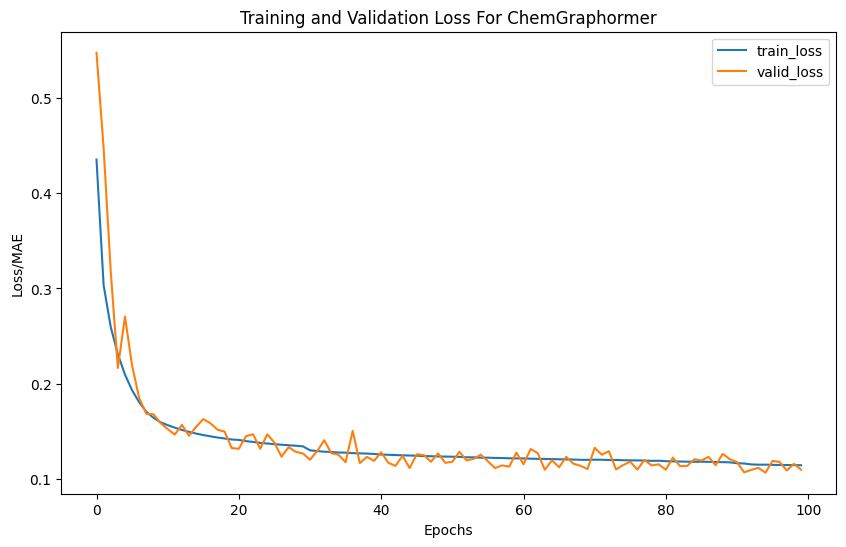

In [ ]:
# plot the layer-wise schedular for each layer in one graph

fig = plt.figure(figsize=(10,6))
plt.plot(chemgraph['Train Loss'], label='train_loss')
plt.plot(chemgraph['Val MAE'], label='valid_loss')
plt.xlabel('Epochs')
plt.ylabel('Loss/MAE')
plt.title('Training and Validation Loss For ChemGraphormer')

plt.legend()
plt.grid(visible=False)
plt.show()

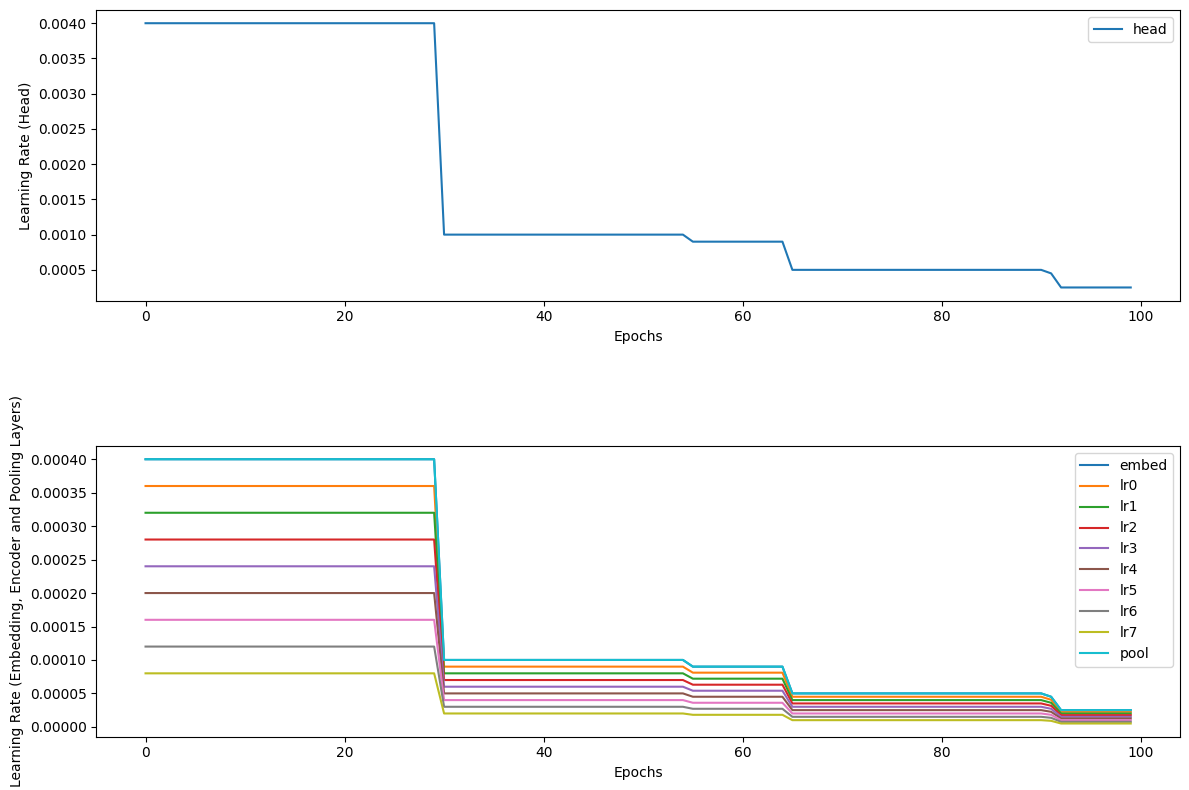

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2, 1, 1)
plt.plot(chemgraph['LR Head'], label='head')
plt.ylabel('Learning Rate (Head)')
plt.xlabel('Epochs')
plt.legend()
plt.grid(visible=False)


plt.subplot(2, 1, 2)
plt.plot(chemgraph['LR Embed'], label='embed')
plt.plot(chemgraph['LR Layer0'], label='lr0')
plt.plot(chemgraph['LR Layer1'], label='lr1')
plt.plot(chemgraph['LR Layer2'], label='lr2')
plt.plot(chemgraph['LR Layer3'], label='lr3')
plt.plot(chemgraph['LR Layer4'], label='lr4')
plt.plot(chemgraph['LR Layer5'], label='lr5')
plt.plot(chemgraph['LR Layer6'], label='lr6')
plt.plot(chemgraph['LR Layer7'], label='lr7')
plt.plot(chemgraph['LR Pool'], label='pool')
plt.xlabel('Epochs')
plt.ylabel('Learning Rate (Embedding, Encoder and Pooling Layers)')
plt.legend()
plt.grid(visible=False)

plt.tight_layout()
plt.subplots_adjust(hspace=0.5)
plt.show()

In [ ]:
##  ALL DONE

## THANK YOU